In [1]:
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

def analyze_trip_correlation(dataset_type='clean', save_path='../reports/figures/correlation_matrix_heatmap.png'):
    """
    Extracts derived variables (trip_duration, fare_amount, trip_distance, speed) 
    from either the 'clean' or 'raw' dataset using DuckDB, computes the Pearson 
    correlation matrix, and plots/saves a heatmap.
    
    Parameters:
    - dataset_type (str): Either 'clean' (for processed clean parquet) or 'raw' (for raw dataset).
    - save_path (str): File path to save the generated correlation heatmap image.
    """
    # Configure plotting style
    sns.set_theme(style="whitegrid")
    plt.rcParams.update({
        'font.family': 'serif',
        'font.size': 11,
        'axes.labelsize': 12,
        'axes.titlesize': 14,
        'xtick.labelsize': 10,
        'ytick.labelsize': 10,
        'figure.autolayout': True
    })

    # Select file path dynamically based on input type
    if dataset_type.lower() == 'clean':
        file_path = '../data/processed/yellow_tripdata_2025_clean.parquet'
    elif dataset_type.lower() == 'raw':
        file_path = '../data/raw/yellow_tripdata_2025-*.parquet'
    else:
        raise ValueError("dataset_type must be either 'clean' or 'raw'")

    # Connect to DuckDB in-memory
    con = duckdb.connect(database=':memory:')

    print(f"Extracting derived variables from '{dataset_type}' dataset ({file_path})...")

    # Query to derive trip_duration and speed on the fly
    query = f"""
    WITH derived AS (
        SELECT 
            trip_distance,
            fare_amount,
            EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 AS trip_duration,
            CASE 
                WHEN EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) > 0 
                THEN trip_distance / (EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 3600.0)
                ELSE NULL 
            END AS speed
        FROM '{file_path}'
    )
    SELECT trip_distance, fare_amount, trip_duration, speed
    FROM derived
    """

    df_sample = con.execute(query).df()
    con.close()

    # Compute the Pearson correlation matrix using Pandas
    corr_matrix = df_sample[['trip_duration', 'fare_amount', 'trip_distance', 'speed']].corr()

    print("\n--- Correlation Matrix Summary ---")
    print(corr_matrix.to_string())

    # Generate a heatmap visualization for the correlation matrix
    print("\nGenerating correlation matrix heatmap...")
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        corr_matrix, 
        annot=True, 
        fmt=".3f", 
        cmap="Blues", 
        cbar=True,
        square=True,
        linewidths=0.5,
        vmin=-1, 
        vmax=1
    )

    if save_path:
        plt.savefig(save_path, dpi=300)
        print(f"Correlation matrix heatmap successfully saved to '{save_path}'!")
        
    plt.show()
    
    return df_sample, corr_matrix

# Example usage:
# df_clean, corr_clean = analyze_trip_correlation(dataset_type='clean')
# df_raw, corr_raw = analyze_trip_correlation(dataset_type='raw')

Extracting derived variables from 'raw' dataset (../data/raw/yellow_tripdata_2025-*.parquet)...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


--- Correlation Matrix Summary ---
               trip_duration  fare_amount  trip_distance     speed
trip_duration       1.000000     0.042510       0.003433 -0.000254
fare_amount         0.042510     1.000000       0.000682  0.000026
trip_distance       0.003433     0.000682       1.000000  0.792017
speed              -0.000254     0.000026       0.792017  1.000000

Generating correlation matrix heatmap...
Correlation matrix heatmap successfully saved to '../reports/figures/correlation_matrix_heatmap_raw.png'!


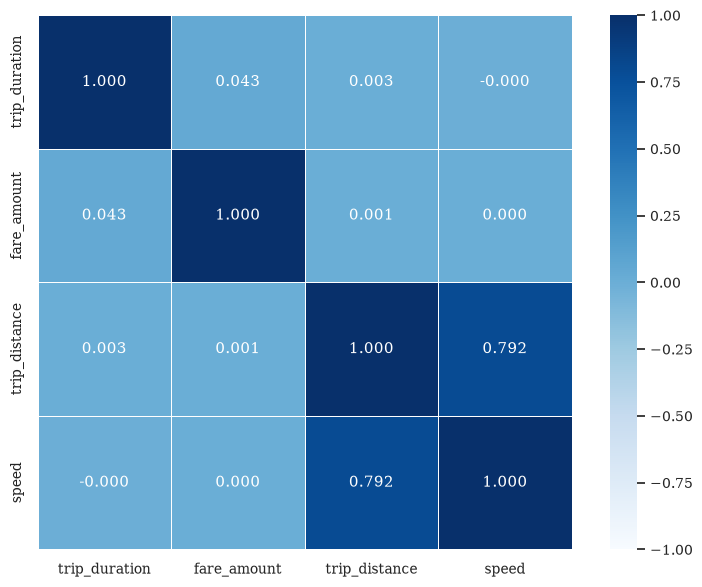

In [2]:
df_raw, corr_raw = analyze_trip_correlation(dataset_type='raw', save_path='../reports/figures/correlation_matrix_heatmap_raw.png')

Extracting derived variables from 'clean' dataset (../data/processed/yellow_tripdata_2025_clean.parquet)...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


--- Correlation Matrix Summary ---
               trip_duration  fare_amount  trip_distance     speed
trip_duration       1.000000     0.092384       0.782291  0.226356
fare_amount         0.092384     1.000000       0.104990  0.063352
trip_distance       0.782291     0.104990       1.000000  0.688438
speed               0.226356     0.063352       0.688438  1.000000

Generating correlation matrix heatmap...
Correlation matrix heatmap successfully saved to '../reports/figures/correlation_matrix_heatmap_clean.png'!


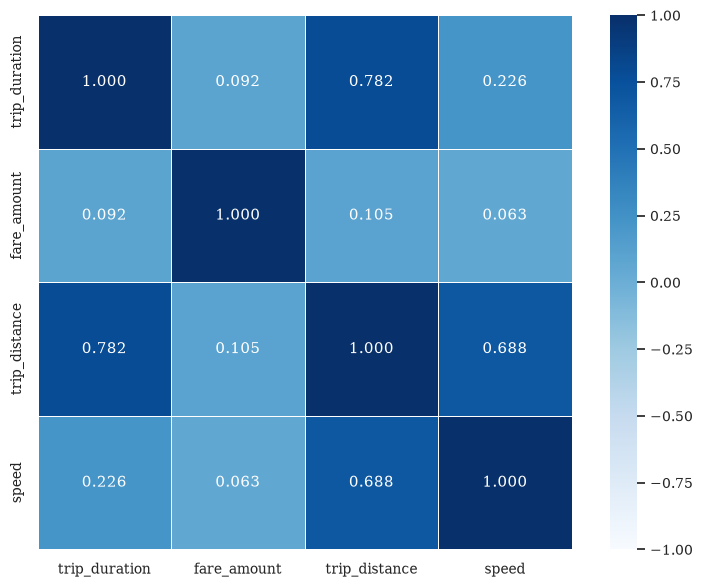

In [3]:
df_clean, corr_clean = analyze_trip_correlation(dataset_type='clean', save_path='../reports/figures/correlation_matrix_heatmap_clean.png')

In [9]:
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


def plot_pairwise_scatter_matrix(
    dataset_type="clean",
    sample_size=50000,
    save_path="../reports/figures/pairwise_scatter_matrix.png",
):
    """Generates and saves a pairwise scatter plot matrix for trip metrics.

    Parameters:
    - dataset_type (str): Either 'clean' (for processed clean parquet) or 'raw'
    (for raw dataset).
    - sample_size (int): Number of records to sample for plotting. Default is
    50,000.
    - save_path (str): File path to save the generated pairplot image.
    """
    # Configure plotting style
    sns.set_theme(style="whitegrid")
    plt.rcParams.update({
        "font.family": "serif",
        "font.size": 11,
        "axes.labelsize": 12,
        "axes.titlesize": 14,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "figure.autolayout": True,
    })

    # Dynamically set target dataset path based on input
    if dataset_type.lower() == "clean":
        file_path = "../data/processed/yellow_tripdata_2025_clean.parquet"
    elif dataset_type.lower() == "raw":
        file_path = "../data/raw/yellow_tripdata_2025-*.parquet"
    else:
        raise ValueError("dataset_type must be either 'clean' or 'raw'")

    # Connect to DuckDB in-memory
    con = duckdb.connect(database=":memory:")

    print(
        f"Extracting derived variables (trip_distance, fare_amount,"
        f" trip_duration, speed) from '{dataset_type}' dataset ({file_path})..."
    )

    # Query to derive trip_duration and speed dynamically
    query = f"""
    WITH derived AS (
        SELECT 
            trip_distance,
            fare_amount,
            EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 AS trip_duration,
            CASE 
                WHEN EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) > 0 
                THEN trip_distance / (EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 3600.0)
                ELSE NULL 
            END AS speed
        FROM '{file_path}'
    )
    SELECT trip_distance, fare_amount, trip_duration, speed
    FROM derived
    USING SAMPLE {sample_size};
    """

    df_sample = con.execute(query).df()
    con.close()

    print(
        f"Loaded {len(df_sample):,} sampled records. Generating pairwise"
        " scatter plot matrix..."
    )

    # Rename columns for clean plot labels
    df_sample.columns = [
        "Distance (mi)",
        "Fare ($)",
        "Duration (min)",
        "Speed (mph)",
    ]

    # Generate pairplot (scatter plots for every pair, KDE on diagonal)
    g = sns.pairplot(
        df_sample,
        kind="scatter",
        diag_kind="kde",
        plot_kws={"alpha": 0.3, "s": 15, "color": "#2D557D"},
        diag_kws={"color": "#14233C", "fill": True},
    )

    dataset_label = "Cleaned" if dataset_type.lower() == "clean" else "Raw"
    g.fig.suptitle(
        f"Pairwise Scatter Plot Matrix ({dataset_label} Data): Distance, Fare,"
        " Duration, and Speed",
        y=1.02,
        fontsize=14,
        fontweight="bold",
    )

    if save_path:
        plt.savefig(save_path, dpi=300)
        print(f"Pairwise scatter matrix successfully saved to '{save_path}'!")

    plt.show()

    return df_sample

Extracting derived variables (trip_distance, fare_amount, trip_duration, speed) from 'raw' dataset (../data/raw/yellow_tripdata_2025-*.parquet)...
Loaded 50,000 sampled records. Generating pairwise scatter plot matrix...
Pairwise scatter matrix successfully saved to '../reports/figures/pairwise_scatter_matrix_raw.png'!


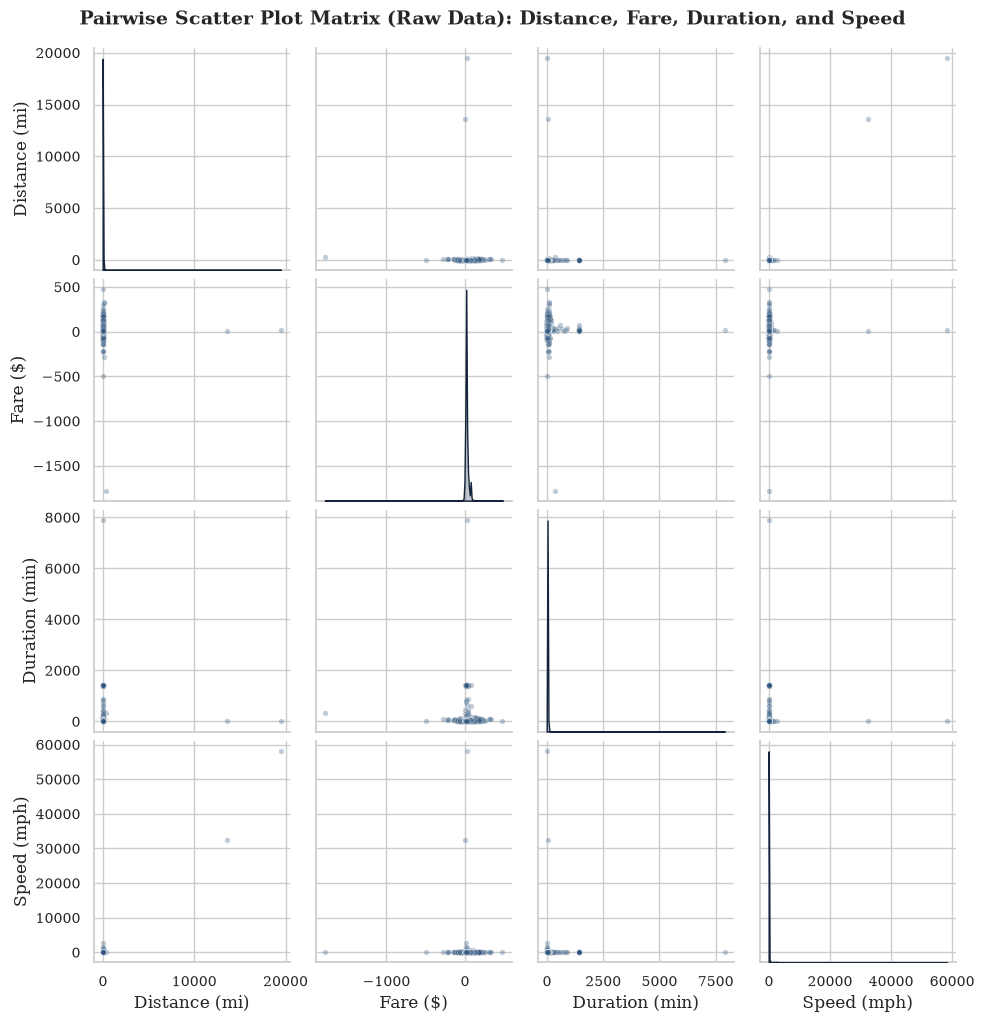

In [10]:
df_raw = plot_pairwise_scatter_matrix(dataset_type='raw', save_path='../reports/figures/pairwise_scatter_matrix_raw.png')

Extracting derived variables (trip_distance, fare_amount, trip_duration, speed) from 'clean' dataset (../data/processed/yellow_tripdata_2025_clean.parquet)...
Loaded 50,000 sampled records. Generating pairwise scatter plot matrix...
Pairwise scatter matrix successfully saved to '../reports/figures/pairwise_scatter_matrix_clean.png'!


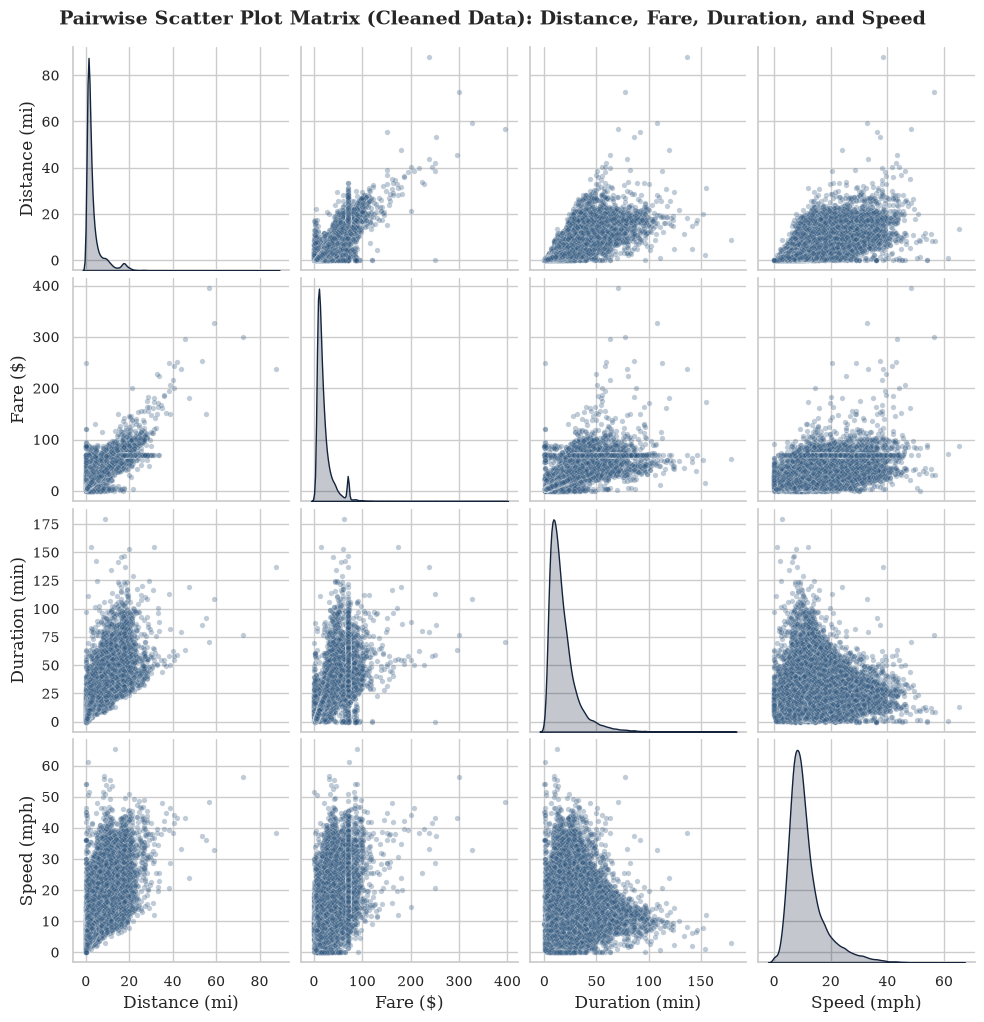

In [23]:
df_clean = plot_pairwise_scatter_matrix(dataset_type='clean', save_path='../reports/figures/pairwise_scatter_matrix_clean.png', sample_size=50000)

In [ ]:
df_raw = plot_pairwise_scatter_matrix(dataset_type='raw', save_path='../reports/figures/pairwise_scatter_matrix_raw.png')

Extracting derived variables (trip_distance, fare_amount, trip_duration, speed) for pairwise plots...
Loaded 50,000 sampled records. Generating pairwise scatter plot matrix...


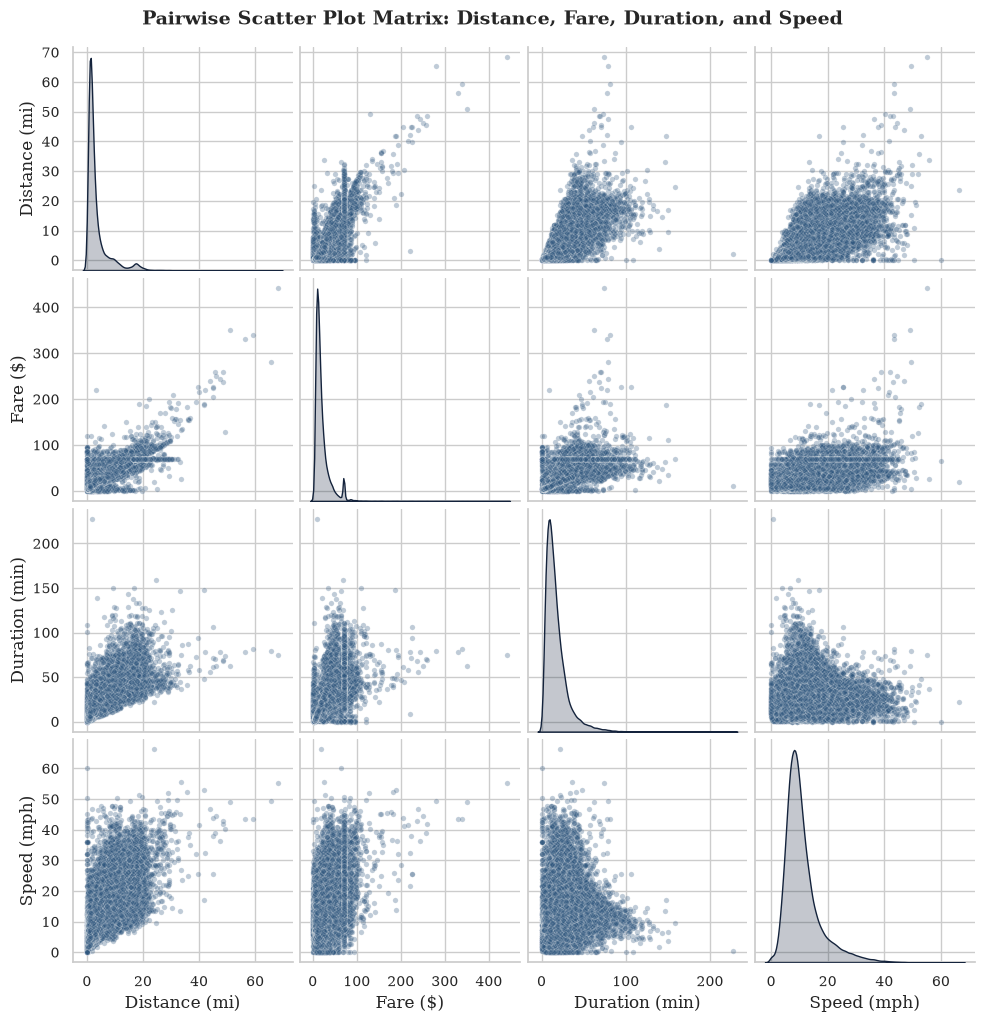

Pairwise scatter matrix successfully saved to '../reports/figures/pairwise_scatter_matrix.png'!


In [21]:
import duckdb

import matplotlib.pyplot as plt

import pandas as pd

import seaborn as sns



# Configure plotting style

sns.set_theme(style="whitegrid")

plt.rcParams.update({

    'font.family': 'serif',

    'font.size': 11,

    'axes.labelsize': 12,

    'axes.titlesize': 14,

    'xtick.labelsize': 10,

    'ytick.labelsize': 10,

    'figure.autolayout': True

})



# Connect to DuckDB in-memory

con = duckdb.connect(database=':memory:')



print("Extracting derived variables (trip_distance, fare_amount, trip_duration, speed) for pairwise plots...")



# Query to derive trip_duration and speed from processed parquet files

query = """

WITH derived AS (

    SELECT

        trip_distance,

        fare_amount,

        EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 60.0 AS trip_duration,

        CASE

            WHEN EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) > 0

            THEN trip_distance / (EXTRACT(EPOCH FROM (tpep_dropoff_datetime - tpep_pickup_datetime)) / 3600.0)

            ELSE NULL

        END AS speed

    FROM '../data/processed/*.parquet'

)

SELECT trip_distance, fare_amount, trip_duration, speed

FROM derived

USING SAMPLE 50000;

"""



df_sample = con.execute(query).df()

con.close()



print(f"Loaded {len(df_sample):,} sampled records. Generating pairwise scatter plot matrix...")



# Rename columns for clean plot labels

df_sample.columns = ['Distance (mi)', 'Fare ($)', 'Duration (min)', 'Speed (mph)']



# Generate pairplot (scatter plots for every pair, KDE on diagonal)

g = sns.pairplot(

    df_sample,

    kind='scatter',

    diag_kind='kde',

    plot_kws={'alpha': 0.3, 's': 15, 'color': '#2D557D'},

    diag_kws={'color': '#14233C', 'fill': True}

)



g.fig.suptitle('Pairwise Scatter Plot Matrix: Distance, Fare, Duration, and Speed', y=1.02, fontsize=14, fontweight='bold')



plt.savefig('../reports/figures/pairwise_scatter_matrix.png', dpi=300)

plt.show()



print("Pairwise scatter matrix successfully saved to '../reports/figures/pairwise_scatter_matrix.png'!")